# 单资产尾部风险：肥尾的事实与 VaR / ES 估计方法的回测

对应整理稿第一、二章。分两部分：

1. **核对整理稿的事实陈述**：上证50 单日跌幅超过 5% 的频率与正态分布的预测；周跌幅超过 10% 的事件。
2. **哪种单资产 VaR / ES 估计方法可靠？** 在 7 类资产上做滚动的样本外预测并回测。

| 方法 | 做法 | 是否随波动率调整 |
|---|---|---|
| 历史模拟 | 过去 1000 日损失的经验分位与超出均值 | 否 |
| 正态 | 过去 1000 日均值、标准差 | 否 |
| t 分布 | 过去 1000 日极大似然拟合 Student-t（每 21 日重估） | 否 |
| GPD | 对过去 1000 日超过 90% 分位的损失拟合广义帕累托分布（整理稿 2.1.1 节的 POT 方法） | 否 |
| GARCH-FHS | GJR-GARCH(1,1) 预测明日波动率 × 标准化残差的经验分位 | 是 |
| GARCH-EVT | GJR-GARCH(1,1) 预测明日波动率 × 标准化残差尾部的 GPD 分位（McNeil & Frey 2000） | 是 |

回测指标：99% VaR 的突破率与 Kupiec 检验（频率对不对）、Christoffersen 检验（突破是否扎堆）；
97.5% ES 的 Acerbi–Szekely Z2 检验（< −0.70 表示 ES 被显著低估）与「突破日实际平均损失 / 预测 ES」。

## 0 · 环境与数据

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kurtosis, norm, skew
%run ../../01_methods.ipynb

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({
    "figure.figsize": (13, 4),
    "axes.unicode_minus": False,
    "font.sans-serif": ["PingFang SC", "Heiti TC", "Arial Unicode MS", "SimHei", "DejaVu Sans"],
})

ASSETS = {"上证50": "上证50", "沪深300": "沪深300", "中证500": "中证500", "中债综合财富": "中债综合",
          "黄金(GLD×美元兑人民币)": "黄金", "标普500": "标普500", "布伦特原油": "原油"}
RET = {short: to_returns(load_series(name).to_frame()).iloc[:, 0].dropna()
       for name, short in ASSETS.items()}
pd.DataFrame({a: {"起点": r.index.min().date(), "终点": r.index.max().date(), "天数": len(r)} for a, r in RET.items()}).T

,起点,终点,天数
上证50,2004-01-05,2026-10-20,5533
沪深300,2002-01-07,2026-10-12,6005
中证500,2005-01-05,2026-10-12,5284
中债综合,2002-01-07,2026-10-12,6193
黄金,2004-11-19,2026-10-16,5510
标普500,2004-01-05,2026-10-16,5736
原油,1987-05-21,2026-10-14,9107


---
# 1 · 核对整理稿的事实陈述

整理稿：上证50（全收益）「自编制以来共发生过 41 次日度跌幅超过 5% 的情况，频率约 1%，而在拟合的正态分布中概率仅为 0.1%」；
「历史上共发生过 7 次上证50 周度收益率低于 −10% 的事件」，分别在 2008 年（3 次）、2015 年（3 次）和 2018 年 2 月。
这里用上证50 价格指数（免费数据中没有全收益指数；分红对单日、单周大跌的影响很小）。

In [2]:
r50 = RET["上证50"]
px50 = load_series("上证50")
weekly = px50.resample("W-FRI").last().pct_change().dropna()
rows = {}
for label, sub in [("全部（2004 – 2026-10）", r50), ("截至 2019 年末", r50.loc[:"2019-12-31"])]:
    n = int((sub < -0.05).sum())
    rows[label] = {"日跌幅 > 5% 的次数": n, "实际频率": n / len(sub),
                   "正态分布预测的频率": norm.cdf(-0.05, sub.mean(), sub.std())}
pd.DataFrame(rows).T.style.format({"实际频率": "{:.2%}", "正态分布预测的频率": "{:.3%}"})

,日跌幅 > 5% 的次数,实际频率,正态分布预测的频率
全部（2004 – 2026-10）,44.000000,0.80%,0.065%
截至 2019 年末,40.000000,1.03%,0.161%


In [3]:
big = weekly[weekly < -0.10]
print(f"周跌幅 > 10% 共 {len(big)} 次：")
big.to_frame("周收益").style.format("{:.2%}")

周跌幅 > 10% 共 7 次：


,周收益
date,
2008-04-18 00:00:00,-12.36%
2008-06-13 00:00:00,-14.03%
2008-10-10 00:00:00,-15.64%
2015-06-19 00:00:00,-13.35%
2015-07-31 00:00:00,-10.21%
2015-08-21 00:00:00,-11.86%
2018-02-09 00:00:00,-10.78%


**判读**：整理稿的事实陈述成立。

- 周跌幅超过 10% 的 7 次事件，日期与整理稿完全一致。
- 截至 2019 年末，单日跌幅超过 5% 共 40 次，频率 1.03%，正态分布预测 0.16%，与整理稿的「41 次、约 1%、0.1%」基本一致
  （差 1 次可能来自全收益指数与价格指数，或统计截止日的不同）。算到 2026 年 10 月为 44 次，频率 0.80%。

## 1.1 各资产的肥尾程度

峰度（正态为 0）、偏度，以及用 GPD 拟合损失尾部（超过 90% 分位）得到的形状参数 ξ：ξ > 0 表示厚尾，
ξ 越大尾部越厚（ξ = 1/ν 对应自由度 ν 的 t 分布）。

In [4]:
rows = {}
for a, r in RET.items():
    u, xi, beta, n, nu = gpd_fit(-r.values)
    rows[a] = {"年化波动": r.std() * np.sqrt(244), "偏度": skew(r), "超额峰度": kurtosis(r),
               "日跌幅 > 3σ 实际频率": (r < r.mean() - 3 * r.std()).mean(), "正态预测": norm.cdf(-3),
               "GPD 形状参数 ξ": xi}
pd.DataFrame(rows).T.style.format({"年化波动": "{:.1%}", "偏度": "{:.2f}", "超额峰度": "{:.1f}",
                                   "日跌幅 > 3σ 实际频率": "{:.2%}", "正态预测": "{:.2%}", "GPD 形状参数 ξ": "{:.2f}"})

,年化波动,偏度,超额峰度,日跌幅 > 3σ 实际频率,正态预测,GPD 形状参数 ξ
上证50,24.4%,-0.09,4.6,1.05%,0.13%,0.15
沪深300,24.2%,-0.23,4.6,1.08%,0.13%,0.16
中证500,28.4%,-0.63,3.8,1.50%,0.13%,0.06
中债综合,1.7%,0.12,11.2,1.34%,0.13%,0.14
黄金,17.8%,-0.33,6.6,0.96%,0.13%,0.12
标普500,18.4%,-0.21,13.3,0.89%,0.13%,0.19
原油,41.8%,0.29,36.9,0.64%,0.13%,0.25


---
# 2 · 哪种 VaR / ES 估计方法可靠？

每个交易日用过去 1000 日（约 4 年）的数据预测下一交易日的 99% VaR、97.5% VaR 与 97.5% ES。

In [5]:
FC = {a: rolling_forecasts(r, window=1000) for a, r in RET.items()}
pd.DataFrame({a: {"回测起点": f.index.min().date(), "预测天数": len(f)} for a, f in FC.items()}).T

,回测起点,预测天数
上证50,2008-02-25,4533
沪深300,2006-03-08,5005
中证500,2009-02-23,4284
中债综合,2005-12-30,5193
黄金,2008-11-10,4510
标普500,2007-12-24,4736
原油,1991-05-03,8107


In [6]:
BT = {a: backtest_table(f) for a, f in FC.items()}
tbl = pd.concat(BT, names=["资产", "方法"])
tbl.style.format({"99% VaR 突破率": "{:.2%}", "Kupiec p": "{:.3f}", "突破后次日再突破": "{:.1%}",
                  "Christoffersen p": "{:.3f}", "Z2": "{:+.2f}", "实际损失/预测ES": "{:.2f}"})

## 2.1 汇总：各方法在 7 类资产上通过了几项检验

In [7]:
METHODS = list(BT["沪深300"].index)
summary = pd.DataFrame({m: {
    "Kupiec 通过（p>5%）": sum(BT[a].loc[m, "Kupiec p"] > 0.05 for a in BT),
    "Christoffersen 通过（p>5%）": sum(BT[a].loc[m, "Christoffersen p"] > 0.05 for a in BT),
    "Z2 通过（> −0.70）": sum(BT[a].loc[m, "Z2"] > -0.70 for a in BT),
    "实际损失/预测ES 中位数": np.median([BT[a].loc[m, "实际损失/预测ES"] for a in BT]),
    "99% VaR 突破率中位数": np.median([BT[a].loc[m, "99% VaR 突破率"] for a in BT]),
} for m in METHODS}).T
summary.style.format({"实际损失/预测ES 中位数": "{:.2f}", "99% VaR 突破率中位数": "{:.2%}"})

,Kupiec 通过（p>5%）,Christoffersen 通过（p>5%）,Z2 通过（> −0.70）,实际损失/预测ES 中位数,99% VaR 突破率中位数
历史模拟,5.000000,1.000000,7.000000,1.03,1.22%
正态,0.000000,0.000000,6.000000,1.27,1.83%
t 分布,3.000000,1.000000,7.000000,1.00,1.13%
GPD,5.000000,1.000000,7.000000,1.03,1.12%
GARCH-FHS,7.000000,5.000000,7.000000,1.03,1.07%
GARCH-EVT,7.000000,6.000000,7.000000,1.03,0.97%


**判读**：

- **正态分布最差**：7 类资产的突破率都显著高于 1%，ES 平均低估约 27%。
- **历史模拟、t 分布、GPD** 的突破率大体正确，ES 也基本准确（实际损失/预测 ES 在 1.0 左右），
  但 Christoffersen 检验几乎全部不通过：突破成串出现（突破后次日再突破的概率 4–15%，理论值 1%）。
- **GARCH-FHS 与 GARCH-EVT 最好**：突破率 7/7 通过，扎堆检验 5/7 与 6/7 通过；两者差别很小，
  EVT 在尾部更厚的资产上略稳。黄金是例外，两种 GARCH 方法都没通过扎堆检验。
- Z2 检验在这里区分力很弱：连正态分布都在 6/7 的资产上通过，而它的 ES 实际低估了约 27%。
  判断 ES 是否准确，「实际损失 / 预测 ES」比 Z2 更直观。

---
# 3 · 突破集中在什么时候？

不随波动率调整的方法即使「总的突破率」正确，突破也可能全部挤在危机期间 ——
平时 VaR 过于保守，危机时又远远不够。按年份统计 99% VaR 的突破次数（理论值约每年 2.4 次）：

In [8]:
def yearly_hits(f):
    x = f[("收益", "")]
    return pd.DataFrame({m: (x < -f[(m, "VaR")]).groupby(f.index.year).sum() for m in METHODS})

yearly_hits(FC["沪深300"]).T.style.background_gradient(axis=None, cmap="Reds")

,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
历史模拟,6,14,12,1,0,0,0,2,1,14,2,0,0,0,6,1,2,0,2,1,7
正态,5,19,24,3,3,0,0,2,1,20,5,0,3,2,8,5,5,0,3,2,7
t 分布,5,13,16,2,1,0,0,2,1,15,5,0,0,1,6,2,2,0,1,1,4
GPD,5,15,11,1,0,0,0,2,1,15,4,0,0,1,5,0,2,0,2,1,7
GARCH-FHS,6,8,3,2,2,0,0,2,1,8,5,1,5,1,2,2,1,0,3,3,4
GARCH-EVT,6,8,3,2,2,0,0,2,1,8,5,2,5,1,3,2,2,0,3,2,3


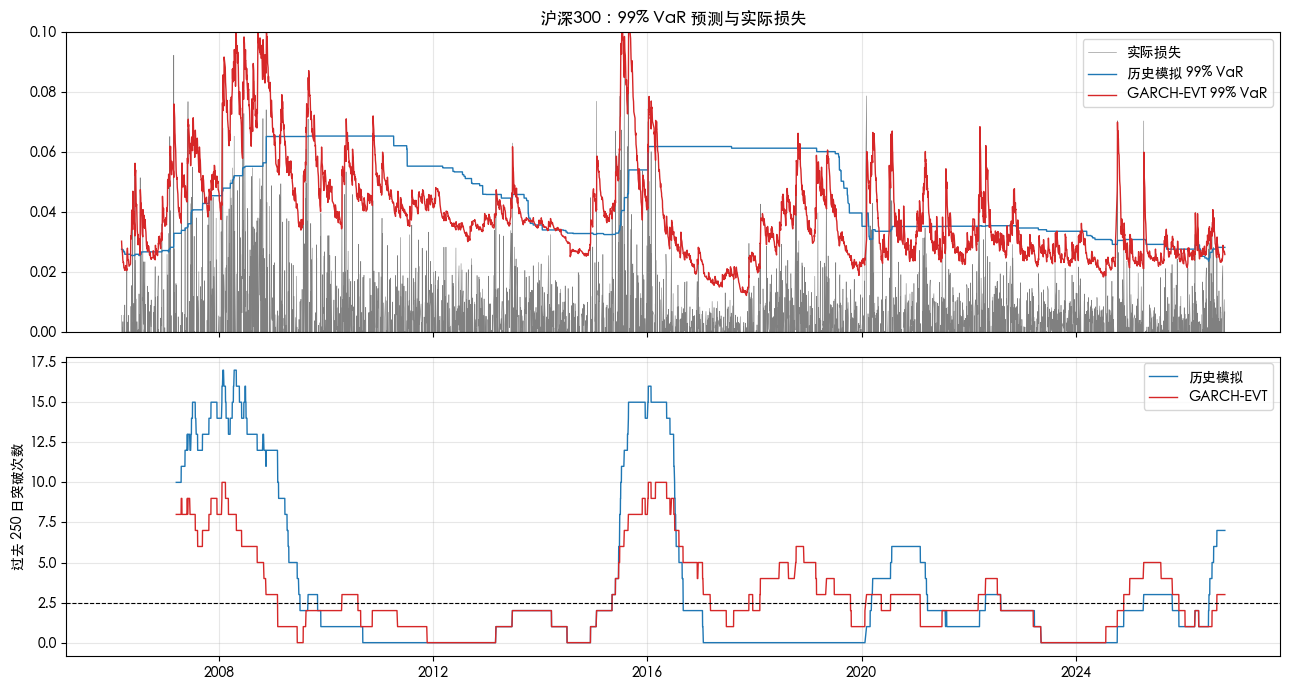

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
f = FC["沪深300"]
axes[0].plot(f.index, -f[("收益", "")], lw=.4, color="gray", label="实际损失")
for m, c in [("历史模拟", "tab:blue"), ("GARCH-EVT", "tab:red")]:
    axes[0].plot(f.index, f[(m, "VaR")], lw=1, color=c, label=f"{m} 99% VaR")
axes[0].set_ylim(0, 0.10); axes[0].legend(loc="upper right"); axes[0].set_title("沪深300：99% VaR 预测与实际损失")
for m, c in [("历史模拟", "tab:blue"), ("GARCH-EVT", "tab:red")]:
    hits = (f[("收益", "")] < -f[(m, "VaR")]).astype(int)
    axes[1].plot(f.index, hits.rolling(250).sum(), lw=1, color=c, label=m)
axes[1].axhline(2.5, color="k", ls="--", lw=.8)
axes[1].set_ylabel("过去 250 日突破次数"); axes[1].legend(loc="upper right")
for ax in axes:
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**判读**：不随波动率调整的方法，突破集中在 2007、2008、2015、2020 等危机年份（历史模拟在 2007、2015 年各 14 次），
平时多数年份为 0 —— 平时过于保守、危机时远远不够。GARCH 类方法的突破在年份之间分布得均匀得多。

---
# 结论

| 问题 | 结论 |
|---|---|
| 整理稿的肥尾事实 | **成立**。上证50 日跌幅 > 5% 的频率约为正态预测的 6–12 倍；7 次周跌幅 > 10% 的事件日期完全一致 |
| 正态分布能否用 | **不能**。7 类资产的 99% VaR 都被突破过多，ES 平均低估约 27% |
| GPD（整理稿介绍的 POT 方法）表现如何 | 总的突破率与 ES 水平基本正确，但不随波动率调整，突破集中在危机期间 |
| 哪种方法最可靠 | **GARCH-EVT**（McNeil & Frey 2000）：先用 GARCH 跟踪波动率，再用 GPD 刻画标准化残差的尾部 |

下方为自动汇总的关键数字。

In [10]:
for m, r in summary.iterrows():
    print(f"{m:10s}：Kupiec {r['Kupiec 通过（p>5%）']:.0f}/7，Christoffersen {r['Christoffersen 通过（p>5%）']:.0f}/7，"
          f"Z2 {r['Z2 通过（> −0.70）']:.0f}/7，实际损失/预测ES 中位数 {r['实际损失/预测ES 中位数']:.2f}")

历史模拟      ：Kupiec 5/7，Christoffersen 1/7，Z2 7/7，实际损失/预测ES 中位数 1.03
正态        ：Kupiec 0/7，Christoffersen 0/7，Z2 6/7，实际损失/预测ES 中位数 1.27
t 分布      ：Kupiec 3/7，Christoffersen 1/7，Z2 7/7，实际损失/预测ES 中位数 1.00
GPD       ：Kupiec 5/7，Christoffersen 1/7，Z2 7/7，实际损失/预测ES 中位数 1.03
GARCH-FHS ：Kupiec 7/7，Christoffersen 5/7，Z2 7/7，实际损失/预测ES 中位数 1.03
GARCH-EVT ：Kupiec 7/7，Christoffersen 6/7，Z2 7/7，实际损失/预测ES 中位数 1.03
